# XGBoost Intensity (MMI) Classifier — Full Data Mmi 0 To 10

Full data with the complete MMI 0–10 class range (separate row filtering for Model A and Model B).

> **Data:** the input CSV is not included in this repository. Place it in Google Drive (or locally) and edit the path in the data-loading cell.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup complete.
  LOADING DATA
  Raw rows loaded : 696,338

  Class distribution (iclass, truncated 0-10):
    MMI  0:      12  ( 0.0%)  
    MMI  1:  28,176  ( 4.0%)  #
    MMI  2: 360,816  (51.8%)  #######################
    MMI  3: 230,015  (33.0%)  ##############
    MMI  4:  56,014  ( 8.0%)  ###
    MMI  5:  12,912  ( 1.9%)  
    MMI  6:   4,921  ( 0.7%)  
    MMI  7:   2,386  ( 0.3%)  
    MMI  8:     942  ( 0.1%)  
    MMI  9:     142  ( 0.0%)  
    MMI 10:       2  ( 0.0%)  

Training Model A (Scenario) ...
  Dropping 1 class(es) with < 10 samples: {10: 2}

  Model A — Scenario (M, dist, VS30)
  Available rows (after dropna) : 567,721
  Training rows                 : 454,175  (80.0%)
  Test rows                     : 113,544  (20.0%)
  MMI classes                   : 10  (MMI 0 to MMI 9)
  Class weights range           : 0.19x to 5161.08x

  Accurac

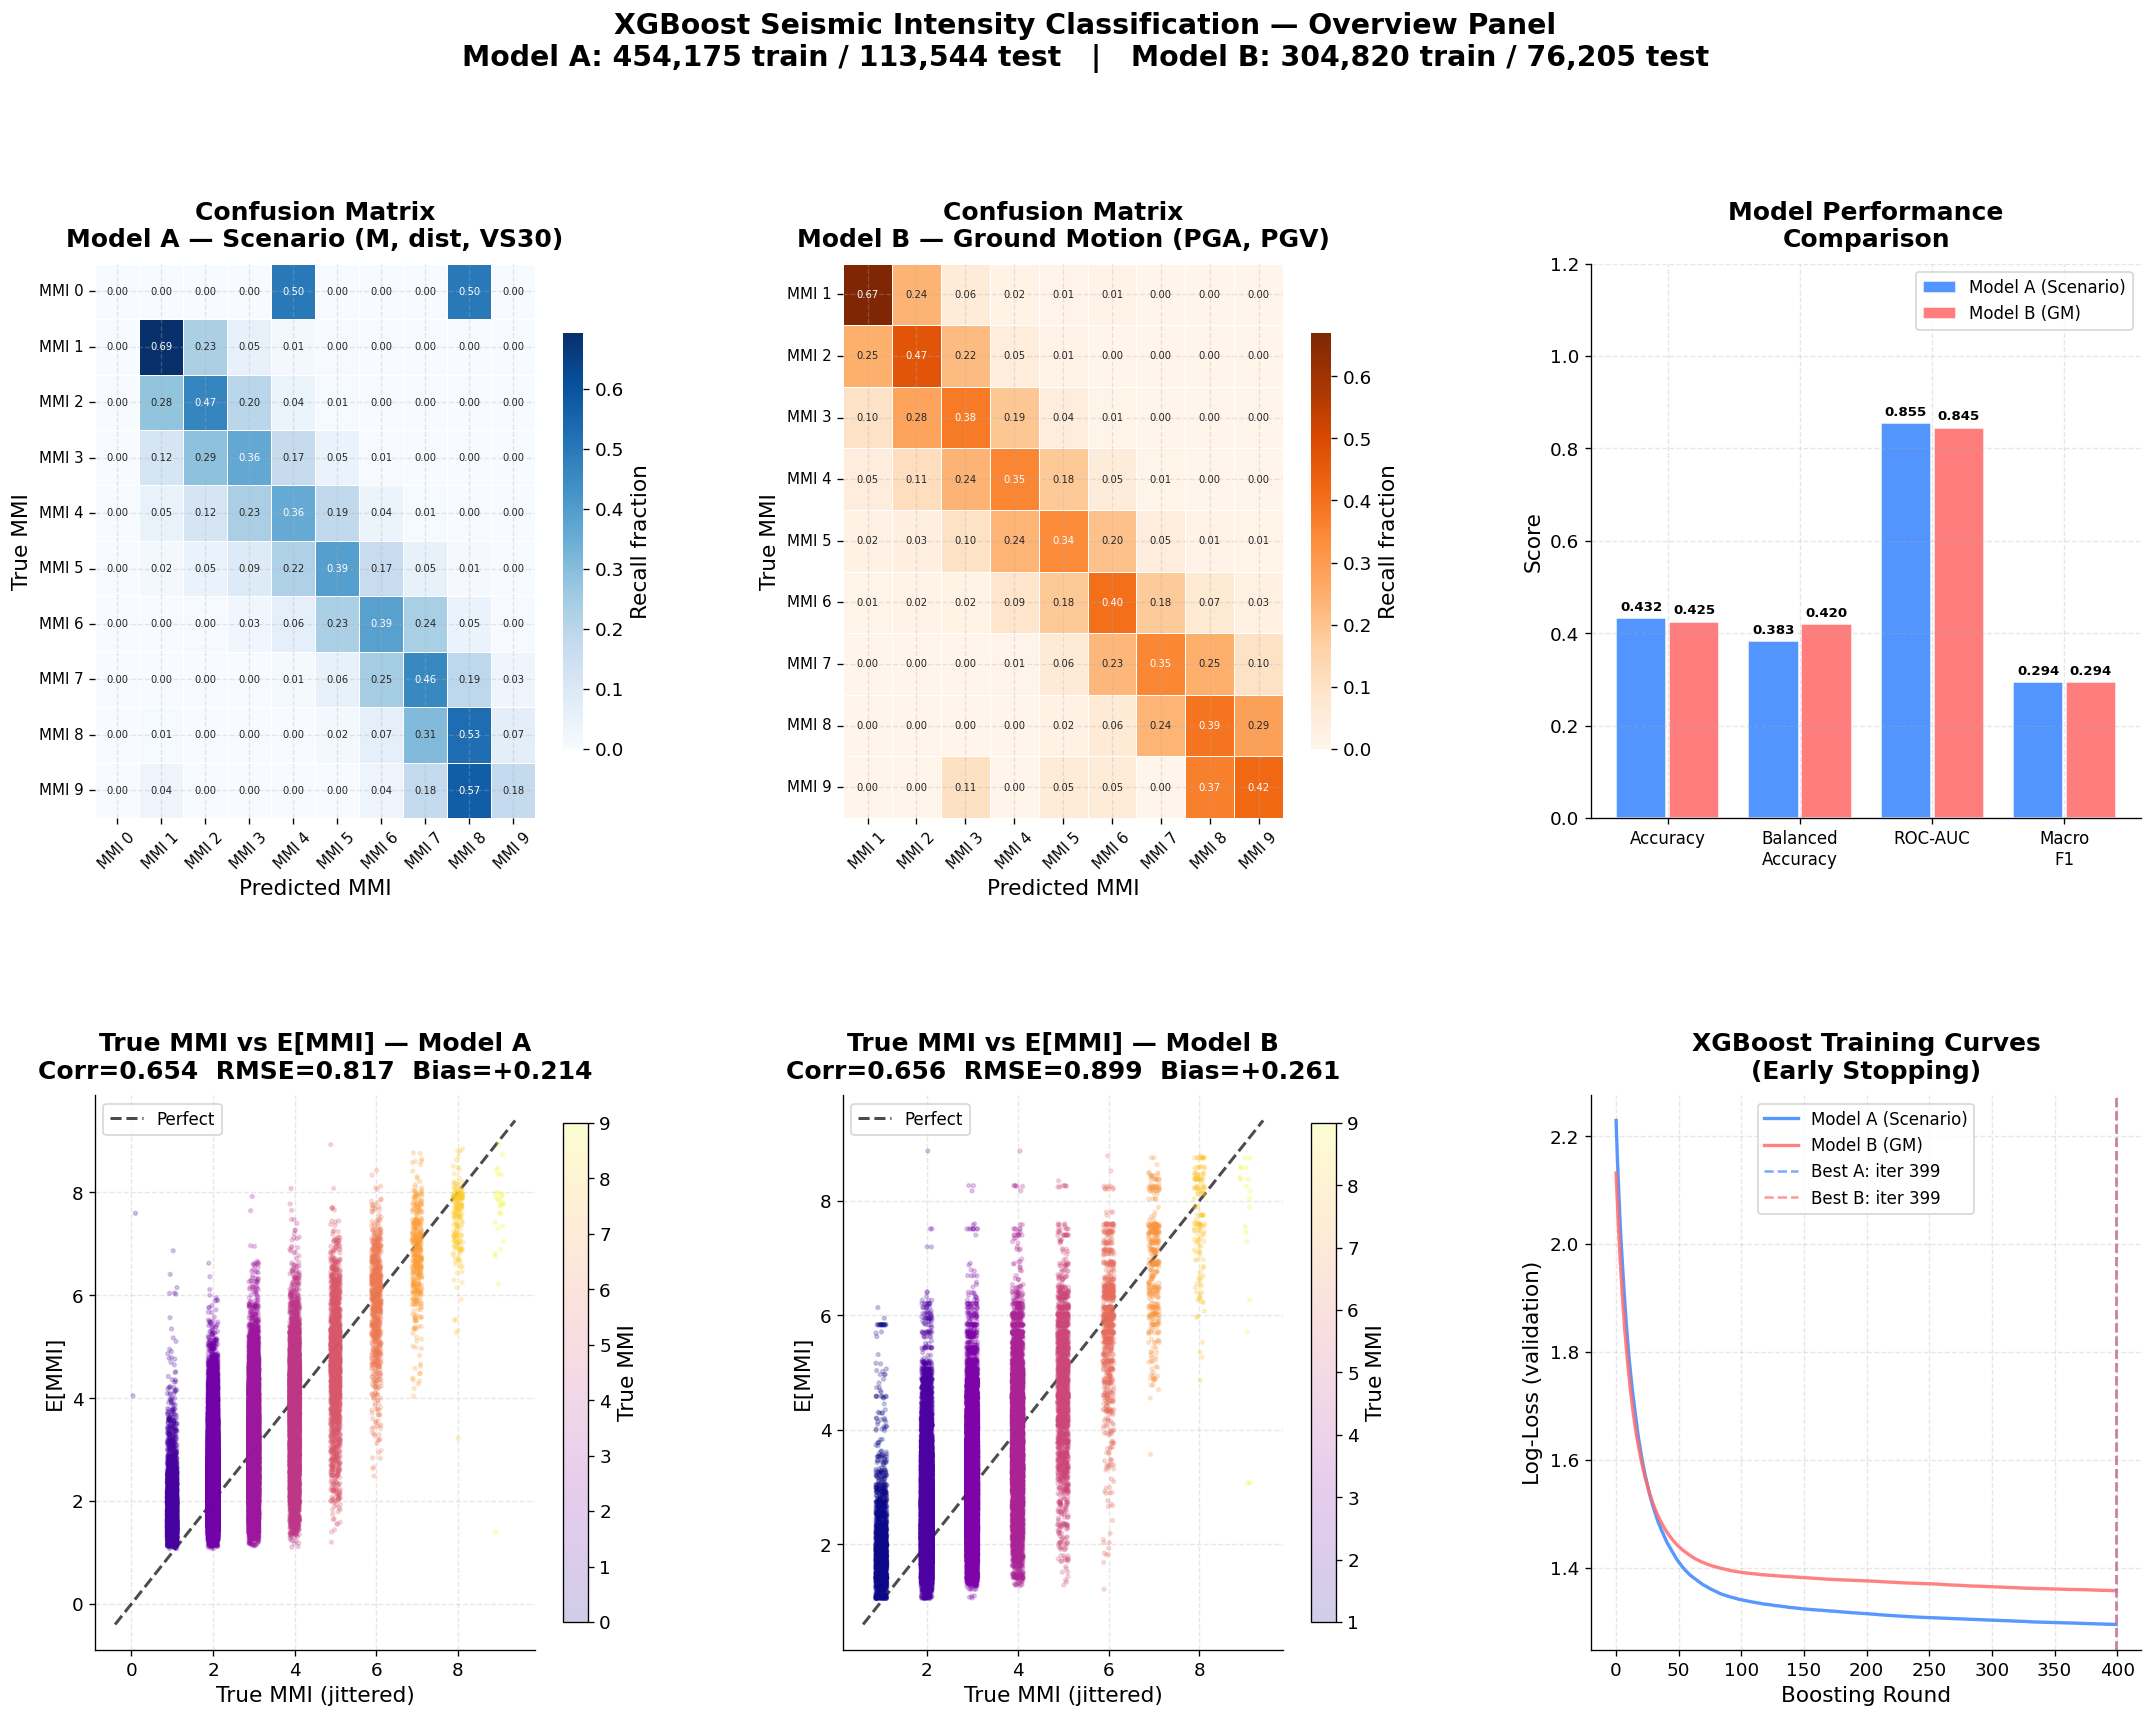

Computing full-data E[MMI] for physical plots ...
  Model A physical plots: 567,721 rows
  Model B physical plots: 381,035 rows


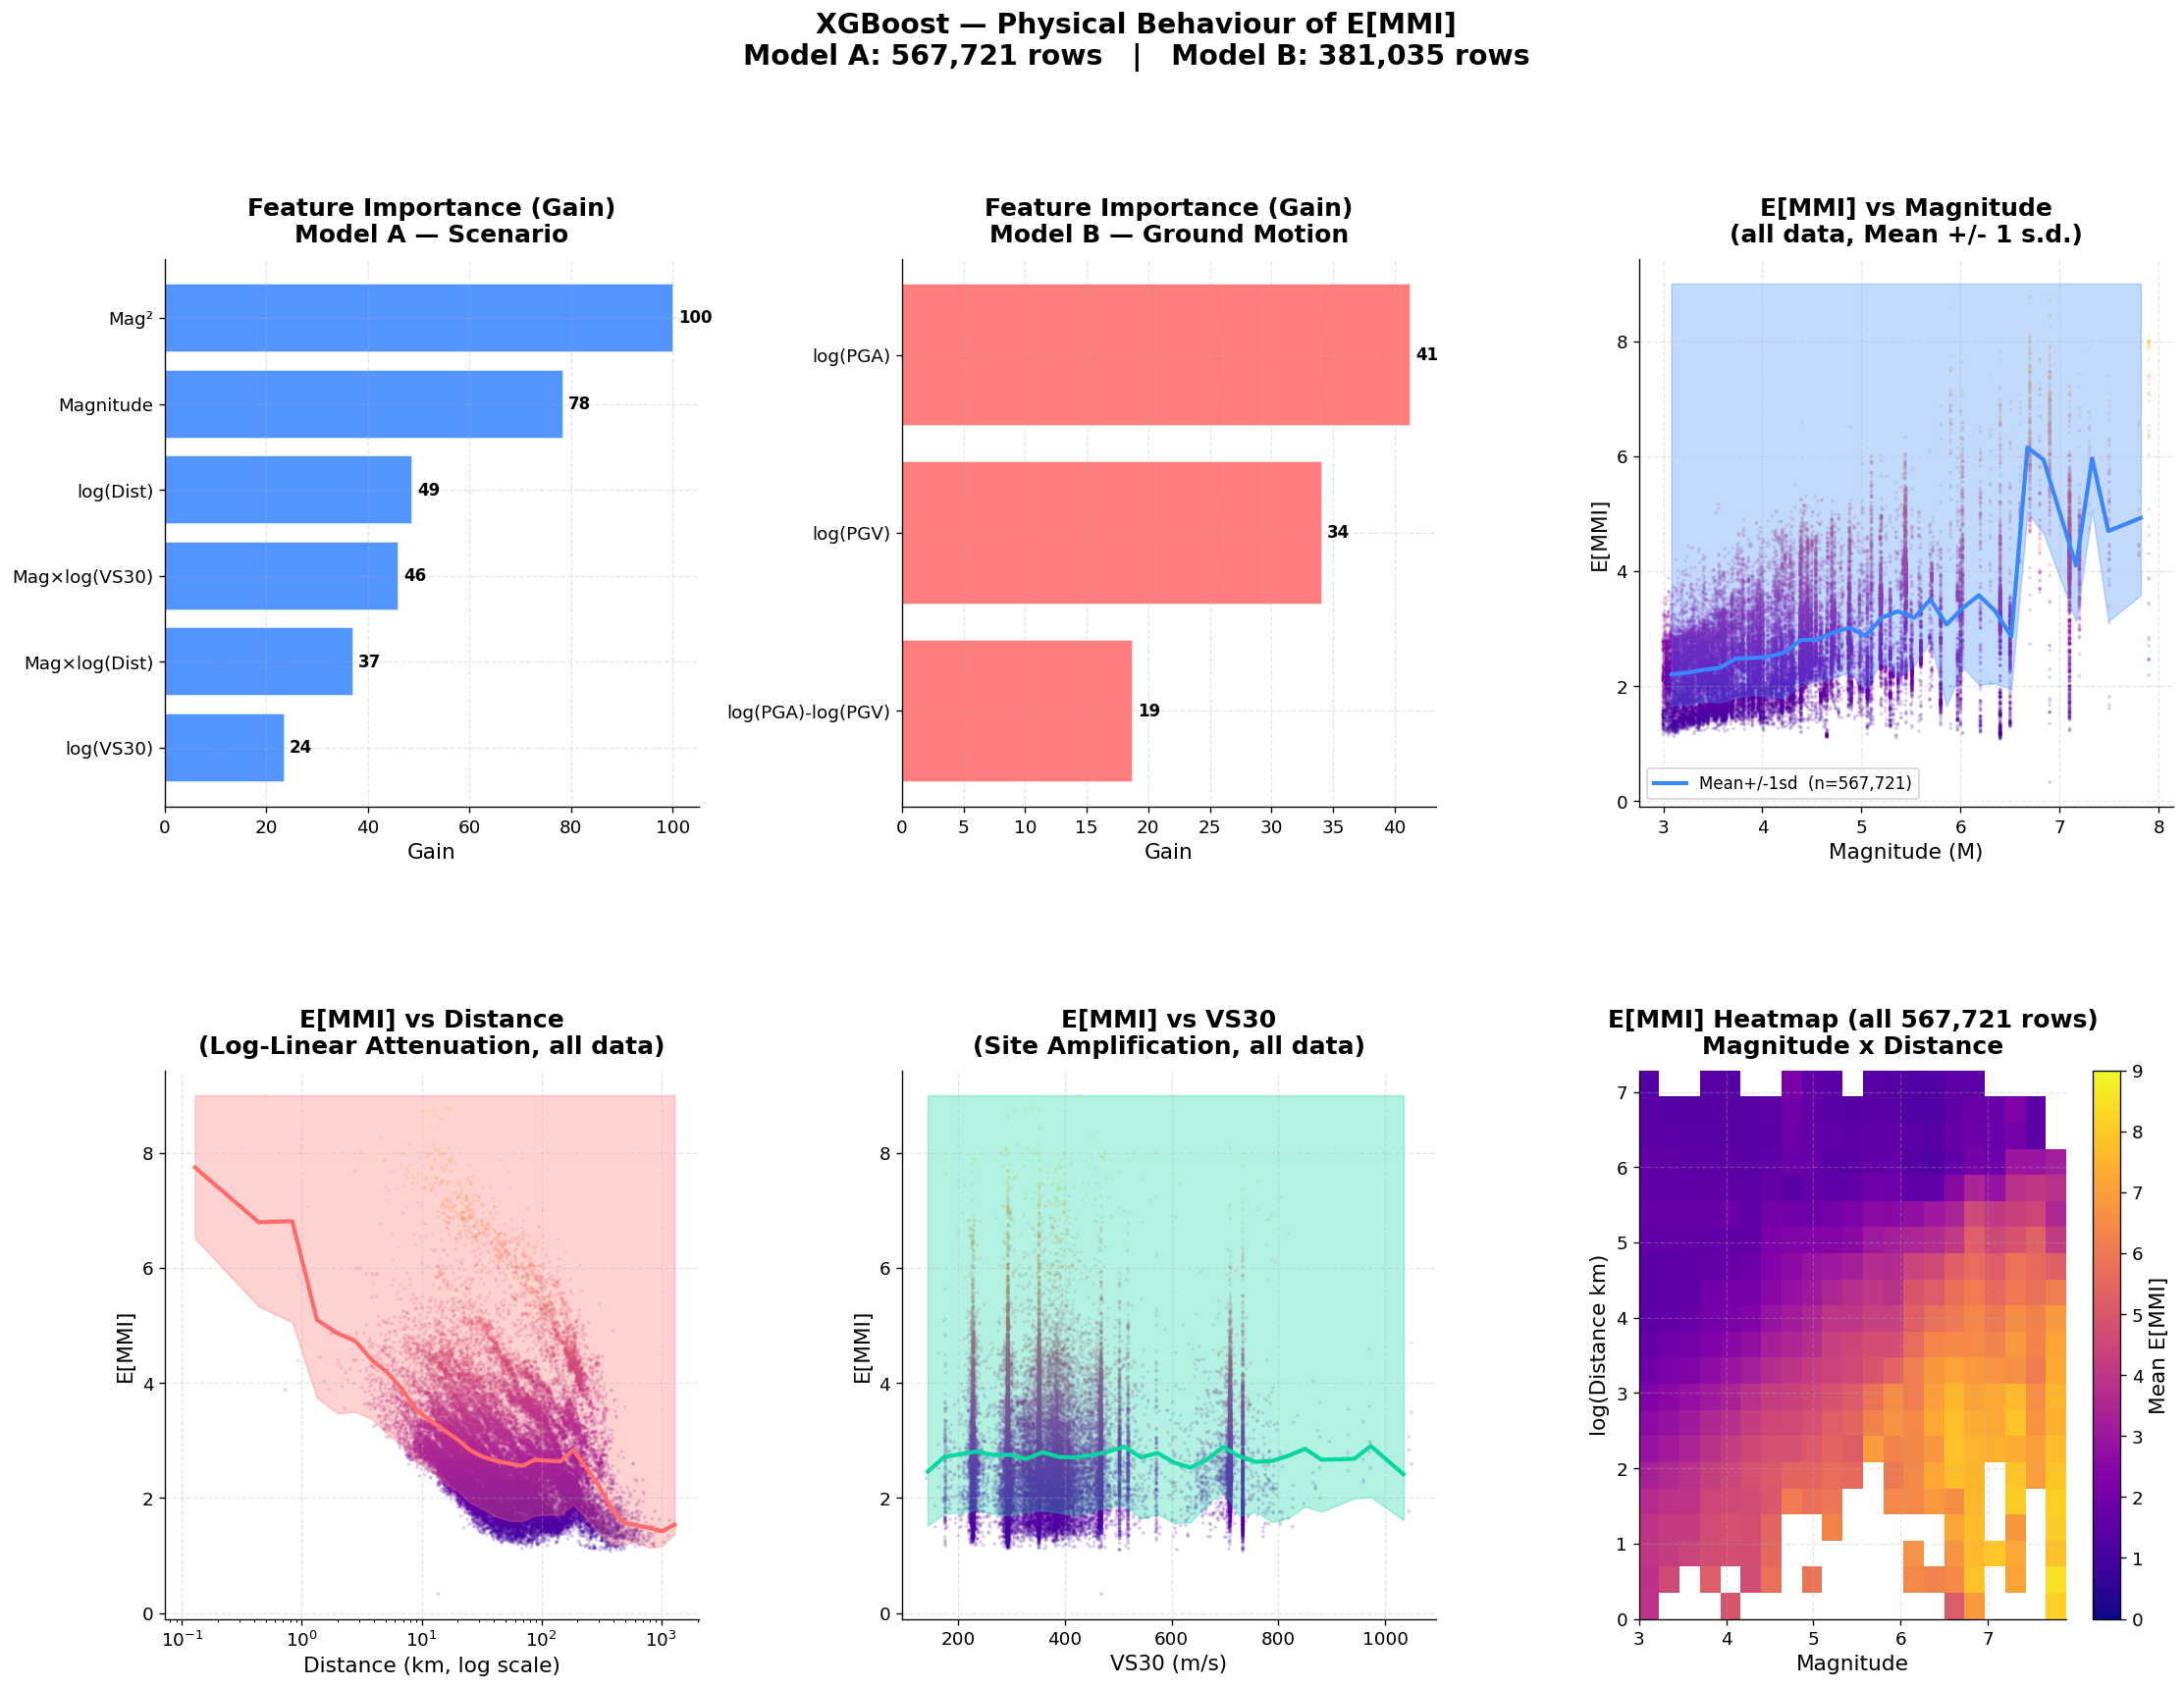

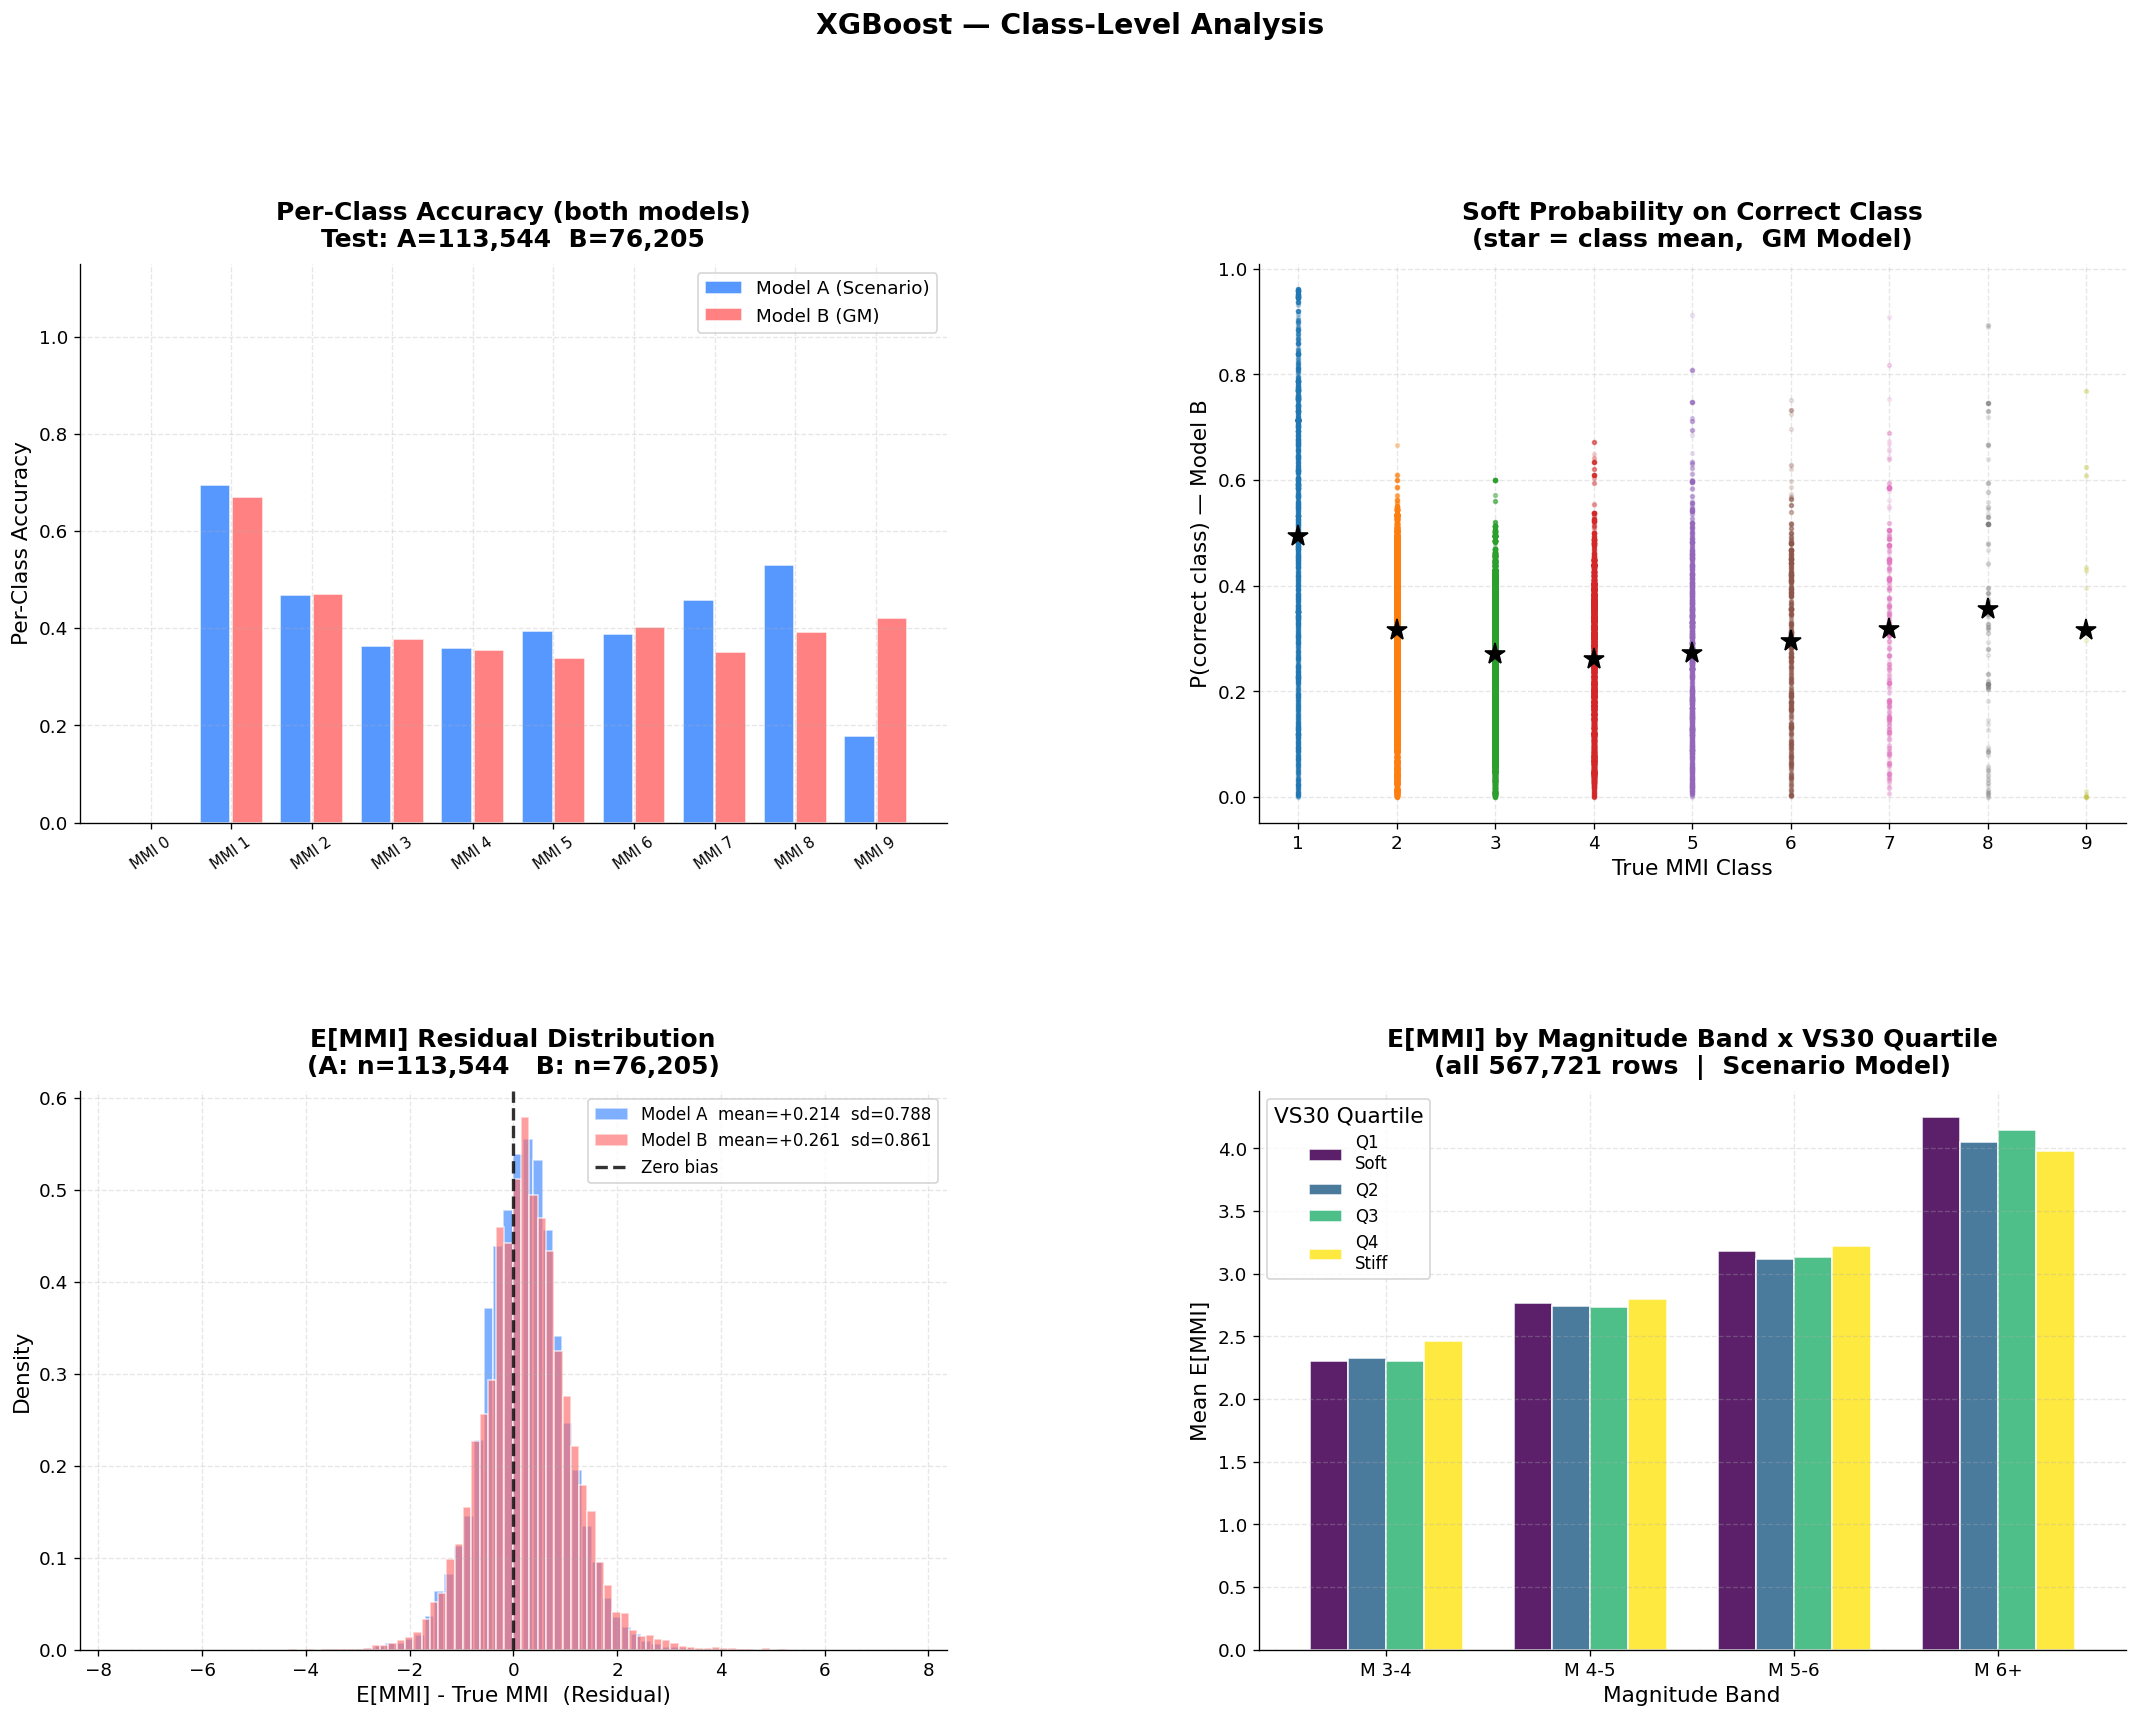


  FINAL SUMMARY

  Model A — Scenario (M, dist, VS30)
    Rows (train / test) : 454,175 / 113,544
    Classes             : 10  (MMI 0 to MMI 9)
    Best XGB iteration  : 399
    Accuracy            : 0.4322
    Balanced Accuracy   : 0.3832
    Weighted F1         : 0.4664
    Macro F1            : 0.2937
    MAE (MMI units)     : 0.6934
    Within +-1 MMI      : 89.1%
    Log-Loss            : 1.2943
    ROC-AUC (macro)     : 0.8547
    E[MMI] Correlation  : 0.6544
    E[MMI] RMSE         : 0.8166
    E[MMI] Bias         : +0.2142

  Model B — Ground Motion (PGA, PGV)
    Rows (train / test) : 304,820 / 76,205
    Classes             : 9  (MMI 1 to MMI 9)
    Best XGB iteration  : 399
    Accuracy            : 0.4251
    Balanced Accuracy   : 0.4199
    Weighted F1         : 0.4535
    Macro F1            : 0.2942
    MAE (MMI units)     : 0.7238
    Within +-1 MMI      : 87.9%
    Log-Loss            : 1.3570
    ROC-AUC (macro)     : 0.8453
    E[MMI] Correlation  : 0.6562
    E[MM

In [ ]:
"""
=============================================================================
XGBOOST INTENSITY CLASSIFIER  —
=============================================================================
DATA FLOW:
  Raw CSV              -> 696,338 rows
  Model A (dropna)     -> 567,721 rows  (80/20 split = 454k train / 113k test)
  Model B (dropna)     -> 381,035 rows  (80/20 split = 304k train /  76k test)

  NO rows are subsampled or discarded.
  All available rows are used for training and ALL panels.

PANELS:
  Panel A — Overview     : confusion matrices, E[MMI] scatter, metrics, training curves
  Panel B — Physical     : feature importance, E[MMI] vs mag/dist/VS30/PGA/PGV, heatmap
  Panel C — Class-Level  : per-class accuracy, P(correct), residuals, VS30 quartiles
=============================================================================
"""

# ─────────────────────────────────────────────────────────────────────────────
# CELL 0  ── Install & magic (run once)
# ─────────────────────────────────────────────────────────────────────────────
# !pip install xgboost scikit-learn matplotlib seaborn pandas numpy -q

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from google.colab import drive
drive.mount("/content/drive")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, log_loss, roc_auc_score,
    classification_report, confusion_matrix,
)
from xgboost import XGBClassifier

# ── Publication-quality style ─────────────────────────────────────────────────
plt.rcParams.update({
    "font.family"      : "DejaVu Sans",
    "font.size"        : 13,
    "axes.titlesize"   : 15,
    "axes.labelsize"   : 13,
    "xtick.labelsize"  : 11,
    "ytick.labelsize"  : 11,
    "legend.fontsize"  : 11,
    "figure.dpi"       : 120,
    "axes.spines.top"  : False,
    "axes.spines.right": False,
    "axes.grid"        : True,
    "grid.alpha"       : 0.3,
    "grid.linestyle"   : "--",
})

CMAP  = "plasma"
C_A   = "#3A86FF"
C_B   = "#FF6B6B"
C_T   = "#06D6A0"
C_AMB = "#F4845F"

print("Setup complete.")

# ─────────────────────────────────────────────────────────────────────────────
# CELL 1  ── Configuration
# ─────────────────────────────────────────────────────────────────────────────
DATA_PATH   = "/content/drive/MyDrive/Colab Notebooks/data/intensityfiles_alldata_March112026.csv"
RANDOM_SEED = 42
TEST_SIZE   = 0.20

# Model A: scenario parameters + interaction terms
FEATURES_A  = ["magnitude", "M2", "log_dist", "log_VS30", "M_logD", "M_logVS30"]
FEAT_A_LBLS = ["Magnitude", "Mag²", "log(Dist)", "log(VS30)",
               "Mag×log(Dist)", "Mag×log(VS30)"]

# Model B: ground motion measures
FEATURES_B  = ["log_PGA", "log_PGV", "PGA_PGV_ratio"]
FEAT_B_LBLS = ["log(PGA)", "log(PGV)", "log(PGA)-log(PGV)"]

XGB_PARAMS = dict(
    n_estimators          = 400,
    max_depth             = 6,
    learning_rate         = 0.08,
    subsample             = 0.80,
    colsample_bytree      = 0.80,
    eval_metric           = "mlogloss",
    tree_method           = "hist",
    early_stopping_rounds = 25,
    random_state          = RANDOM_SEED,
    n_jobs                = -1,
)

# ─────────────────────────────────────────────────────────────────────────────
# CELL 2  ── Load & feature engineering
# ─────────────────────────────────────────────────────────────────────────────
print("=" * 65)
print("  LOADING DATA")
print("=" * 65)

df_raw = pd.read_csv(DATA_PATH, usecols=[
    "magnitude", "intensity", "RRUP_Combined",
    "VS30 (Thompson (2020) geology based Proxies)",
    "PGA (g)", "PGV",
])
df_raw.columns = ["magnitude", "intensity", "distance", "VS30", "PGA", "PGV"]

n_raw = len(df_raw)
print(f"  Raw rows loaded : {n_raw:,}")

# Clean sentinels
df_raw["PGA"] = df_raw["PGA"].where(df_raw["PGA"] > -999).clip(lower=0)
df_raw["PGV"] = df_raw["PGV"].where(df_raw["PGV"] > -999).clip(lower=0)

# Feature engineering
df_raw["log_dist"]      = np.log1p(df_raw["distance"])
df_raw["log_VS30"]      = np.log1p(df_raw["VS30"])
df_raw["log_PGA"]       = np.log1p(df_raw["PGA"])
df_raw["log_PGV"]       = np.log1p(df_raw["PGV"])
df_raw["M2"]            = df_raw["magnitude"] ** 2
df_raw["M_logD"]        = df_raw["magnitude"] * df_raw["log_dist"]
df_raw["M_logVS30"]     = df_raw["magnitude"] * df_raw["log_VS30"]
df_raw["PGA_PGV_ratio"] = df_raw["log_PGA"] - df_raw["log_PGV"]

# Target: TRUNCATE (not round) -> 3.7 becomes 3, preserving 0-10 range
df_raw["iclass"] = df_raw["intensity"].astype(int).clip(0, 10)

print(f"\n  Class distribution (iclass, truncated 0-10):")
class_dist = df_raw["iclass"].value_counts().sort_index()
for c, cnt in class_dist.items():
    bar = "#" * int(cnt / n_raw * 45)
    print(f"    MMI {c:>2}: {cnt:>7,}  ({100*cnt/n_raw:4.1f}%)  {bar}")

# ─────────────────────────────────────────────────────────────────────────────
# CELL 3  ── Build model function (uses ALL available rows)
# ─────────────────────────────────────────────────────────────────────────────
def build_model(df, features, feat_labels, label):
    """
    Train XGBoost on ALL available rows after dropna.
    Returns rich dict with everything needed for all 3 panels.
    """
    # Drop rows with NaN in required features
    sub = df.dropna(subset=features + ["iclass"]).copy()
    n_total = len(sub)

    X_raw = sub[features].values
    le    = LabelEncoder()
    y_enc = le.fit_transform(sub["iclass"])

    # Remove classes too rare to survive a stratified 80/20 split.
    # With TEST_SIZE=0.20 we need at least ceil(1/0.20)=5 samples per class
    # so each split gets >= 1 representative. Use 10 as a safe margin.
    MIN_SAMPLES = max(10, int(np.ceil(1.0 / TEST_SIZE)) + 1)
    counts   = np.bincount(y_enc, minlength=len(le.classes_))
    keep_cls = np.where(counts >= MIN_SAMPLES)[0]
    dropped  = np.where(counts < MIN_SAMPLES)[0]
    if len(dropped):
        orig_cls = le.classes_
        print(f"  Dropping {len(dropped)} class(es) with < {MIN_SAMPLES} samples: "
              f"{ {int(orig_cls[i]): int(counts[i]) for i in dropped} }")
    mask     = np.isin(y_enc, keep_cls)
    X_raw, y_enc = X_raw[mask], y_enc[mask]
    sub      = sub.iloc[mask].copy()

    # Remap to contiguous 0..n-1
    active = sorted(set(y_enc.tolist()))
    remap  = {old: new for new, old in enumerate(active)}
    y      = np.array([remap[v] for v in y_enc])
    classes = le.classes_[active]   # original MMI integers
    n_cls   = len(classes)

    # Class weights: inverse frequency
    cls_counts = np.bincount(y, minlength=n_cls)
    weights    = cls_counts.sum() / (n_cls * cls_counts + 1e-9)
    sw         = np.array([weights[yi] for yi in y])

    # 80/20 stratified split — ALL rows go into train or test
    X_tr, X_te, y_tr, y_te, sw_tr, _ = train_test_split(
        X_raw, y, sw,
        test_size    = TEST_SIZE,
        stratify     = y,
        random_state = RANDOM_SEED,
    )
    # Also split metadata for physical analysis
    sub_tr, sub_te = train_test_split(
        sub, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_SEED)

    print(f"\n{'='*60}")
    print(f"  {label}")
    print(f"{'='*60}")
    print(f"  Available rows (after dropna) : {n_total:,}")
    print(f"  Training rows                 : {len(X_tr):,}  ({100*len(X_tr)/n_total:.1f}%)")
    print(f"  Test rows                     : {len(X_te):,}  ({100*len(X_te)/n_total:.1f}%)")
    print(f"  MMI classes                   : {n_cls}  (MMI {classes[0]} to MMI {classes[-1]})")
    print(f"  Class weights range           : {weights.min():.2f}x to {weights.max():.2f}x")

    # Fit XGBoost
    clf = XGBClassifier(objective="multi:softprob", num_class=n_cls, **XGB_PARAMS)
    clf.fit(X_tr, y_tr,
            sample_weight = sw_tr,
            eval_set      = [(X_te, y_te)],
            verbose       = False)

    # Predictions
    y_pred  = clf.predict(X_te)
    y_proba = clf.predict_proba(X_te)

    # E[MMI] = sum_i  MMI_i * P(MMI_i | x)
    mmi_vals = classes.astype(float)
    E_mmi    = (y_proba * mmi_vals).sum(axis=1)
    true_mmi = classes[y_te].astype(float)

    # Metrics
    acc     = accuracy_score(y_te, y_pred)
    bal_acc = balanced_accuracy_score(y_te, y_pred)
    wf1     = f1_score(y_te, y_pred, average="weighted", zero_division=0)
    mf1     = f1_score(y_te, y_pred, average="macro",    zero_division=0)
    mae     = mean_absolute_error(classes[y_te], classes[y_pred])
    within1 = np.mean(np.abs(classes[y_te] - classes[y_pred]) <= 1) * 100
    ll      = log_loss(y_te, y_proba, labels=list(range(n_cls)))
    try:
        # Use only classes present in y_te to avoid binarization shape mismatch
        te_cls_uniq = sorted(set(y_te.tolist()))
        if len(te_cls_uniq) >= 2:
            auc = roc_auc_score(
                label_binarize(y_te, classes=te_cls_uniq),
                y_proba[:, te_cls_uniq],
                multi_class="ovr", average="macro")
        else:
            auc = float("nan")
    except Exception:
        auc = float("nan")

    corr_e = np.corrcoef(true_mmi, E_mmi)[0, 1]
    rmse_e = np.sqrt(np.mean((true_mmi - E_mmi)**2))
    bias_e = (E_mmi - true_mmi).mean()

    print(f"\n  Accuracy          : {acc:.4f}")
    print(f"  Balanced Accuracy : {bal_acc:.4f}")
    print(f"  Weighted F1       : {wf1:.4f}")
    print(f"  Macro F1          : {mf1:.4f}")
    print(f"  MAE (MMI units)   : {mae:.4f}")
    print(f"  Within +-1 MMI    : {within1:.1f}%")
    print(f"  Log-Loss          : {ll:.4f}")
    print(f"  ROC-AUC (macro)   : {auc:.4f}")
    print(f"  E[MMI] Corr       : {corr_e:.4f}  RMSE: {rmse_e:.4f}  Bias: {bias_e:+.4f}")
    print(f"  Best XGB iter     : {clf.best_iteration}")
    print()
    # Classes present in the test set (subset when rare classes have 0 test samples)
    te_classes = sorted(set(y_te.tolist()))
    print(classification_report(
        y_te, y_pred,
        labels       = te_classes,
        target_names = [f"MMI {int(classes[i])}" for i in te_classes],
        zero_division = 0,
    ))

    return {
        "clf"      : clf,
        "le"       : le,
        "classes"  : classes,
        "n_cls"    : n_cls,
        "mmi_vals" : mmi_vals,
        "X_tr"     : X_tr, "X_te"  : X_te,
        "y_tr"     : y_tr, "y_te"  : y_te,
        "y_pred"   : y_pred,
        "y_proba"  : y_proba,
        "E_mmi"    : E_mmi,
        "true_mmi" : true_mmi,
        "sub_te"   : sub_te,
        "sub"      : sub,     # full dataset for physical plots
        "features" : features,
        "feat_lbls": feat_labels,
        "metrics"  : {
            "acc": acc, "bal_acc": bal_acc, "wf1": wf1,
            "mf1": mf1, "mae": mae, "within1": within1,
            "ll": ll, "auc": auc, "corr_e": corr_e,
            "rmse_e": rmse_e, "bias_e": bias_e,
        },
    }

# Train both models
print("\nTraining Model A (Scenario) ...")
R_A = build_model(df_raw, FEATURES_A, FEAT_A_LBLS, "Model A — Scenario (M, dist, VS30)")

print("\nTraining Model B (Ground Motion) ...")
R_B = build_model(df_raw, FEATURES_B, FEAT_B_LBLS, "Model B — Ground Motion (PGA, PGV)")

# ─────────────────────────────────────────────────────────────────────────────
# CELL 4  ── Helper: binned mean +/- 1 sd
# ─────────────────────────────────────────────────────────────────────────────
def bin_stats(x, y, n_bins=30, log_x=False):
    xb    = np.log1p(x) if log_x else x
    edges = np.linspace(xb.min(), xb.max(), n_bins + 1)
    mids, means, stds = [], [], []
    for i in range(len(edges) - 1):
        m = (xb >= edges[i]) & (xb < edges[i+1])
        if m.sum() >= 10:
            mids.append((edges[i] + edges[i+1]) / 2)
            means.append(y[m].mean())
            stds.append(y[m].std())
    return np.array(mids), np.array(means), np.array(stds)

def expected_mmi_full(clf, X, mmi_vals):
    """Run predict_proba on a large array and return E[MMI]."""
    proba = clf.predict_proba(X)
    return (proba * mmi_vals).sum(axis=1)

# ─────────────────────────────────────────────────────────────────────────────
# CELL 5  ── PANEL A  —  OVERVIEW
# ─────────────────────────────────────────────────────────────────────────────
n_A, n_B = R_A["n_cls"], R_B["n_cls"]
use_n    = max(n_A, n_B)
ann_fs   = max(6, 9 - use_n // 3)

fig = plt.figure(figsize=(22, 15))
fig.suptitle(
    "XGBoost Seismic Intensity Classification — Overview Panel\n"
    f"Model A: {len(R_A['X_tr']):,} train / {len(R_A['X_te']):,} test   |   "
    f"Model B: {len(R_B['X_tr']):,} train / {len(R_B['X_te']):,} test",
    fontsize=17, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.50, wspace=0.36)

# A1  Confusion matrix — Model A
ax = fig.add_subplot(gs[0, 0])
cls_lbl_A = [f"MMI {int(c)}" for c in R_A["classes"]]
sns.heatmap(
    confusion_matrix(R_A["y_te"], R_A["y_pred"],
                     labels=list(range(n_A)), normalize="true"),
    ax=ax, annot=True, fmt=".2f", cmap="Blues", cbar=True,
    xticklabels=cls_lbl_A, yticklabels=cls_lbl_A,
    linewidths=0.35, linecolor="white", annot_kws={"size": ann_fs},
    cbar_kws={"shrink": 0.75, "label": "Recall fraction"},
)
ax.set_title("Confusion Matrix\nModel A — Scenario (M, dist, VS30)",
             fontweight="bold", pad=10)
ax.set_xlabel("Predicted MMI"); ax.set_ylabel("True MMI")
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)

# A2  Confusion matrix — Model B
ax = fig.add_subplot(gs[0, 1])
cls_lbl_B = [f"MMI {int(c)}" for c in R_B["classes"]]
sns.heatmap(
    confusion_matrix(R_B["y_te"], R_B["y_pred"],
                     labels=list(range(n_B)), normalize="true"),
    ax=ax, annot=True, fmt=".2f", cmap="Oranges", cbar=True,
    xticklabels=cls_lbl_B, yticklabels=cls_lbl_B,
    linewidths=0.35, linecolor="white", annot_kws={"size": ann_fs},
    cbar_kws={"shrink": 0.75, "label": "Recall fraction"},
)
ax.set_title("Confusion Matrix\nModel B — Ground Motion (PGA, PGV)",
             fontweight="bold", pad=10)
ax.set_xlabel("Predicted MMI"); ax.set_ylabel("True MMI")
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)

# A3  Metric comparison bar chart
ax = fig.add_subplot(gs[0, 2])
met_names = ["Accuracy", "Balanced\nAccuracy", "ROC-AUC", "Macro\nF1"]
vals_A = [R_A["metrics"][k] for k in ("acc","bal_acc","auc","mf1")]
vals_B = [R_B["metrics"][k] for k in ("acc","bal_acc","auc","mf1")]
x = np.arange(4)
b1 = ax.bar(x - 0.2, vals_A, 0.38, label="Model A (Scenario)",
            color=C_A, alpha=0.88, edgecolor="white")
b2 = ax.bar(x + 0.2, vals_B, 0.38, label="Model B (GM)",
            color=C_B, alpha=0.88, edgecolor="white")
for bar in list(b1) + list(b2):
    h = bar.get_height()
    if not np.isnan(h):
        ax.text(bar.get_x()+bar.get_width()/2, h+0.01, f"{h:.3f}",
                ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(met_names, fontsize=10)
ax.set_ylim(0, 1.20); ax.set_ylabel("Score")
ax.set_title("Model Performance\nComparison", fontweight="bold", pad=10)
ax.legend(fontsize=10)

# A4  E[MMI] scatter — Model A
ax = fig.add_subplot(gs[1, 0])
jit = np.random.uniform(-0.12, 0.12, len(R_A["true_mmi"]))
sc = ax.scatter(R_A["true_mmi"]+jit, R_A["E_mmi"],
                c=R_A["true_mmi"], cmap=CMAP, alpha=0.2, s=5, zorder=3)
lo_v = R_A["mmi_vals"].min()-0.4; hi_v = R_A["mmi_vals"].max()+0.4
ax.plot([lo_v,hi_v],[lo_v,hi_v],"k--",lw=1.8,label="Perfect",alpha=0.7)
plt.colorbar(sc, ax=ax, label="True MMI", shrink=0.9)
ax.set_xlabel("True MMI (jittered)"); ax.set_ylabel("E[MMI]")
m = R_A["metrics"]
ax.set_title(f"True MMI vs E[MMI] — Model A\n"
             f"Corr={m['corr_e']:.3f}  RMSE={m['rmse_e']:.3f}  Bias={m['bias_e']:+.3f}",
             fontweight="bold", pad=10)
ax.legend(fontsize=10)

# A5  E[MMI] scatter — Model B
ax = fig.add_subplot(gs[1, 1])
jit2 = np.random.uniform(-0.12, 0.12, len(R_B["true_mmi"]))
sc2 = ax.scatter(R_B["true_mmi"]+jit2, R_B["E_mmi"],
                 c=R_B["true_mmi"], cmap=CMAP, alpha=0.2, s=5, zorder=3)
lo_v2 = R_B["mmi_vals"].min()-0.4; hi_v2 = R_B["mmi_vals"].max()+0.4
ax.plot([lo_v2,hi_v2],[lo_v2,hi_v2],"k--",lw=1.8,label="Perfect",alpha=0.7)
plt.colorbar(sc2, ax=ax, label="True MMI", shrink=0.9)
ax.set_xlabel("True MMI (jittered)"); ax.set_ylabel("E[MMI]")
m2 = R_B["metrics"]
ax.set_title(f"True MMI vs E[MMI] — Model B\n"
             f"Corr={m2['corr_e']:.3f}  RMSE={m2['rmse_e']:.3f}  Bias={m2['bias_e']:+.3f}",
             fontweight="bold", pad=10)
ax.legend(fontsize=10)

# A6  Training log-loss curves
ax = fig.add_subplot(gs[1, 2])
h_A = R_A["clf"].evals_result()["validation_0"]["mlogloss"]
h_B = R_B["clf"].evals_result()["validation_0"]["mlogloss"]
ax.plot(h_A, lw=2, color=C_A, alpha=0.85, label="Model A (Scenario)")
ax.plot(h_B, lw=2, color=C_B, alpha=0.85, label="Model B (GM)")
ax.axvline(R_A["clf"].best_iteration, color=C_A, ls="--", lw=1.5, alpha=0.7,
           label=f"Best A: iter {R_A['clf'].best_iteration}")
ax.axvline(R_B["clf"].best_iteration, color=C_B, ls="--", lw=1.5, alpha=0.7,
           label=f"Best B: iter {R_B['clf'].best_iteration}")
ax.set_xlabel("Boosting Round"); ax.set_ylabel("Log-Loss (validation)")
ax.set_title("XGBoost Training Curves\n(Early Stopping)", fontweight="bold", pad=10)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# CELL 6  ── Full-dataset E[MMI] (all available rows, not just test set)
# ─────────────────────────────────────────────────────────────────────────────
print("Computing full-data E[MMI] for physical plots ...")

sub_A_full = df_raw.dropna(subset=FEATURES_A + ["iclass"]).copy()
sub_B_full = df_raw.dropna(subset=FEATURES_B + ["iclass"]).copy()

sub_A_full["E_mmi"] = expected_mmi_full(
    R_A["clf"], sub_A_full[FEATURES_A].values, R_A["mmi_vals"])
sub_B_full["E_mmi"] = expected_mmi_full(
    R_B["clf"], sub_B_full[FEATURES_B].values, R_B["mmi_vals"])

# Scatter subsample for speed
scat_A = sub_A_full.sample(n=min(40_000, len(sub_A_full)), random_state=9)
scat_B = sub_B_full.sample(n=min(40_000, len(sub_B_full)), random_state=9)

print(f"  Model A physical plots: {len(sub_A_full):,} rows")
print(f"  Model B physical plots: {len(sub_B_full):,} rows")

# ─────────────────────────────────────────────────────────────────────────────
# CELL 7  ── PANEL B  —  PHYSICAL BEHAVIOUR
# ─────────────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(22, 15))
fig.suptitle(
    "XGBoost — Physical Behaviour of E[MMI]\n"
    f"Model A: {len(sub_A_full):,} rows   |   Model B: {len(sub_B_full):,} rows",
    fontsize=17, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.48, wspace=0.38)

mv_A = R_A["mmi_vals"]; mv_B = R_B["mmi_vals"]

# B1  Feature importance — Model A
ax = fig.add_subplot(gs[0, 0])
gi_A   = R_A["clf"].get_booster().get_score(importance_type="gain")
gains_A = [gi_A.get(f"f{i}", 0) for i in range(len(FEATURES_A))]
# sort by gain descending
ord_A  = np.argsort(gains_A)
bars   = ax.barh([FEAT_A_LBLS[i] for i in ord_A],
                 [gains_A[i] for i in ord_A],
                 color=C_A, alpha=0.88, edgecolor="white")
for bar, v in zip(bars, [gains_A[i] for i in ord_A]):
    ax.text(v + max(gains_A)*0.01, bar.get_y()+bar.get_height()/2,
            f"{v:,.0f}", va="center", fontsize=10, fontweight="bold")
ax.set_xlabel("Gain")
ax.set_title("Feature Importance (Gain)\nModel A — Scenario", fontweight="bold", pad=10)

# B2  Feature importance — Model B
ax = fig.add_subplot(gs[0, 1])
gi_B   = R_B["clf"].get_booster().get_score(importance_type="gain")
gains_B = [gi_B.get(f"f{i}", 0) for i in range(len(FEATURES_B))]
ord_B  = np.argsort(gains_B)
bars2  = ax.barh([FEAT_B_LBLS[i] for i in ord_B],
                 [gains_B[i] for i in ord_B],
                 color=C_B, alpha=0.88, edgecolor="white")
for bar, v in zip(bars2, [gains_B[i] for i in ord_B]):
    ax.text(v + max(gains_B)*0.01, bar.get_y()+bar.get_height()/2,
            f"{v:,.0f}", va="center", fontsize=10, fontweight="bold")
ax.set_xlabel("Gain")
ax.set_title("Feature Importance (Gain)\nModel B — Ground Motion", fontweight="bold", pad=10)

# B3  E[MMI] vs Magnitude (all rows, +/- 1 sd)
ax = fig.add_subplot(gs[0, 2])
ax.scatter(scat_A["magnitude"], scat_A["E_mmi"], s=2, alpha=0.12,
           c=scat_A["E_mmi"], cmap=CMAP)
mx, mm, ms = bin_stats(sub_A_full["magnitude"].values, sub_A_full["E_mmi"].values)
ax.fill_between(mx, (mm-ms).clip(mv_A.min()), (mm+ms).clip(mv_A.max()),
                alpha=0.3, color=C_A)
ax.plot(mx, mm, "-", color=C_A, lw=2.5,
        label=f"Mean+/-1sd  (n={len(sub_A_full):,})")
ax.set_xlabel("Magnitude (M)"); ax.set_ylabel("E[MMI]")
ax.set_title("E[MMI] vs Magnitude\n(all data, Mean +/- 1 s.d.)", fontweight="bold", pad=10)
ax.legend(fontsize=10)

# B4  E[MMI] vs Distance (log scale, all rows)
ax = fig.add_subplot(gs[1, 0])
ax.scatter(scat_A["distance"], scat_A["E_mmi"], s=2, alpha=0.12,
           c=scat_A["E_mmi"], cmap=CMAP)
dx, dm, ds = bin_stats(sub_A_full["distance"].values, sub_A_full["E_mmi"].values,
                       log_x=True)
dm_x = np.expm1(dx)
ax.fill_between(dm_x, (dm-ds).clip(mv_A.min()), (dm+ds).clip(mv_A.max()),
                alpha=0.3, color=C_B)
ax.plot(dm_x, dm, "-", color=C_B, lw=2.5)
ax.set_xscale("log")
ax.set_xlabel("Distance (km, log scale)"); ax.set_ylabel("E[MMI]")
ax.set_title("E[MMI] vs Distance\n(Log-Linear Attenuation, all data)",
             fontweight="bold", pad=10)

# B5  E[MMI] vs VS30 (all rows)
ax = fig.add_subplot(gs[1, 1])
ax.scatter(scat_A["VS30"], scat_A["E_mmi"], s=2, alpha=0.12,
           c=scat_A["E_mmi"], cmap=CMAP)
vx, vm, vs_ = bin_stats(sub_A_full["VS30"].values, sub_A_full["E_mmi"].values)
ax.fill_between(vx, (vm-vs_).clip(mv_A.min()), (vm+vs_).clip(mv_A.max()),
                alpha=0.3, color=C_T)
ax.plot(vx, vm, "-", color=C_T, lw=2.5)
ax.set_xlabel("VS30 (m/s)"); ax.set_ylabel("E[MMI]")
ax.set_title("E[MMI] vs VS30\n(Site Amplification, all data)", fontweight="bold", pad=10)

# B6  Heatmap: Magnitude x Distance coloured by E[MMI]
ax = fig.add_subplot(gs[1, 2])
mag_bins  = np.linspace(sub_A_full["magnitude"].min(),
                        sub_A_full["magnitude"].max(), 22)
dist_bins = np.linspace(sub_A_full["log_dist"].min(),
                        sub_A_full["log_dist"].max(), 22)
H,   xe, ye = np.histogram2d(sub_A_full["magnitude"], sub_A_full["log_dist"],
                              bins=[mag_bins, dist_bins],
                              weights=sub_A_full["E_mmi"])
Cnt, _,  _  = np.histogram2d(sub_A_full["magnitude"], sub_A_full["log_dist"],
                              bins=[mag_bins, dist_bins])
Hmean = np.where(Cnt > 0, H/Cnt, np.nan)
im = ax.pcolormesh(xe, ye, Hmean.T, cmap=CMAP,
                   vmin=mv_A.min(), vmax=mv_A.max())
plt.colorbar(im, ax=ax, label="Mean E[MMI]")
ax.set_xlabel("Magnitude"); ax.set_ylabel("log(Distance km)")
ax.set_title(f"E[MMI] Heatmap (all {len(sub_A_full):,} rows)\nMagnitude x Distance",
             fontweight="bold", pad=10)

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# CELL 8  ── PANEL C  —  CLASS-LEVEL ANALYSIS
# ─────────────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(22, 15))
fig.suptitle("XGBoost — Class-Level Analysis", fontsize=17, fontweight="bold", y=1.02)
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.48, wspace=0.36)

# C1  Per-class accuracy (both models on common classes)
ax = fig.add_subplot(gs[0, 0])
# Use the model with more classes for the x-axis
R_ref = R_A if n_A >= n_B else R_B
pca_A, pca_B = [], []
all_mmi = sorted(set(list(R_A["classes"])) | set(list(R_B["classes"])))
for mmi_c in all_mmi:
    # Model A
    if mmi_c in R_A["classes"]:
        i_A = np.where(R_A["classes"] == mmi_c)[0][0]
        m_A = R_A["y_te"] == i_A
        pca_A.append(accuracy_score(R_A["y_te"][m_A], R_A["y_pred"][m_A])
                     if m_A.sum() > 0 else np.nan)
    else:
        pca_A.append(np.nan)
    # Model B
    if mmi_c in R_B["classes"]:
        i_B = np.where(R_B["classes"] == mmi_c)[0][0]
        m_B = R_B["y_te"] == i_B
        pca_B.append(accuracy_score(R_B["y_te"][m_B], R_B["y_pred"][m_B])
                     if m_B.sum() > 0 else np.nan)
    else:
        pca_B.append(np.nan)

x = np.arange(len(all_mmi))
ax.bar(x-0.2, pca_A, 0.38, label="Model A (Scenario)",
       color=C_A, alpha=0.85, edgecolor="white")
ax.bar(x+0.2, pca_B, 0.38, label="Model B (GM)",
       color=C_B, alpha=0.85, edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels([f"MMI {int(c)}" for c in all_mmi], rotation=35, fontsize=9)
ax.set_ylabel("Per-Class Accuracy"); ax.set_ylim(0, 1.15)
ax.set_title(f"Per-Class Accuracy (both models)\nTest: A={len(R_A['y_te']):,}  B={len(R_B['y_te']):,}",
             fontweight="bold", pad=10)
ax.legend()

# C2  P(correct class) vs true MMI — Model B
ax = fig.add_subplot(gs[0, 1])
cpal = sns.color_palette("tab10", n_B)
for i, c in enumerate(R_B["classes"]):
    m = R_B["y_te"] == i
    if m.sum() > 2 and i < R_B["y_proba"].shape[1]:
        probs_c = R_B["y_proba"][m, i]
        ax.scatter([int(c)] * m.sum(), probs_c,
                   alpha=0.15, s=5, color=cpal[i % 10], zorder=2)
        ax.plot(int(c), probs_c.mean(), "k*", ms=13, zorder=5)
ax.set_xlabel("True MMI Class")
ax.set_ylabel("P(correct class) — Model B")
ax.set_xticks([int(c) for c in R_B["classes"]])
ax.set_title("Soft Probability on Correct Class\n(star = class mean,  GM Model)",
             fontweight="bold", pad=10)

# C3  E[MMI] residual histogram (both models)
ax = fig.add_subplot(gs[1, 0])
res_A = R_A["E_mmi"] - R_A["true_mmi"]
res_B = R_B["E_mmi"] - R_B["true_mmi"]
ax.hist(res_A, bins=80, alpha=0.65, color=C_A, density=True, edgecolor="white",
        label=f"Model A  mean={res_A.mean():+.3f}  sd={res_A.std():.3f}")
ax.hist(res_B, bins=80, alpha=0.65, color=C_B, density=True, edgecolor="white",
        label=f"Model B  mean={res_B.mean():+.3f}  sd={res_B.std():.3f}")
ax.axvline(0, color="k", ls="--", lw=2, alpha=0.8, label="Zero bias")
ax.set_xlabel("E[MMI] - True MMI  (Residual)")
ax.set_ylabel("Density")
ax.set_title(f"E[MMI] Residual Distribution\n(A: n={len(R_A['y_te']):,}   B: n={len(R_B['y_te']):,})",
             fontweight="bold", pad=10)
ax.legend(fontsize=10)

# C4  E[MMI] by magnitude band x VS30 quartile (all rows, Model A)
ax = fig.add_subplot(gs[1, 1])
sub_A_full["vs30_q"]   = pd.qcut(sub_A_full["VS30"], 4,
                                  labels=["Q1\nSoft","Q2","Q3","Q4\nStiff"])
mag_edges_4 = [sub_A_full["magnitude"].min(), 4, 5, 6,
               sub_A_full["magnitude"].max() + 0.01]
mag_labels_4 = ["M 3-4", "M 4-5", "M 5-6", "M 6+"]
sub_A_full["mag_band"] = pd.cut(sub_A_full["magnitude"],
                                 bins=mag_edges_4, labels=mag_labels_4)
pivot = (sub_A_full.groupby(["mag_band","vs30_q"], observed=True)["E_mmi"]
                   .mean().unstack())
pivot.plot(kind="bar", ax=ax, colormap="viridis",
           edgecolor="white", width=0.75, alpha=0.88)
ax.set_xlabel("Magnitude Band"); ax.set_ylabel("Mean E[MMI]")
ax.set_xticklabels(mag_labels_4, rotation=0)
ax.set_title(f"E[MMI] by Magnitude Band x VS30 Quartile\n"
             f"(all {len(sub_A_full):,} rows  |  Scenario Model)",
             fontweight="bold", pad=10)
ax.legend(title="VS30 Quartile", fontsize=10)

plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# CELL 9  ── SUMMARY TABLE
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("  FINAL SUMMARY")
print("=" * 65)

for label, R in [("Model A — Scenario (M, dist, VS30)", R_A),
                 ("Model B — Ground Motion (PGA, PGV)", R_B)]:
    m = R["metrics"]
    print(f"\n  {label}")
    print(f"    Rows (train / test) : {len(R['X_tr']):,} / {len(R['X_te']):,}")
    print(f"    Classes             : {R['n_cls']}  "
          f"(MMI {int(R['classes'].min())} to MMI {int(R['classes'].max())})")
    print(f"    Best XGB iteration  : {R['clf'].best_iteration}")
    print(f"    Accuracy            : {m['acc']:.4f}")
    print(f"    Balanced Accuracy   : {m['bal_acc']:.4f}")
    print(f"    Weighted F1         : {m['wf1']:.4f}")
    print(f"    Macro F1            : {m['mf1']:.4f}")
    print(f"    MAE (MMI units)     : {m['mae']:.4f}")
    print(f"    Within +-1 MMI      : {m['within1']:.1f}%")
    print(f"    Log-Loss            : {m['ll']:.4f}")
    print(f"    ROC-AUC (macro)     : {m['auc']:.4f}")
    print(f"    E[MMI] Correlation  : {m['corr_e']:.4f}")
    print(f"    E[MMI] RMSE         : {m['rmse_e']:.4f}")
    print(f"    E[MMI] Bias         : {m['bias_e']:+.4f}")

print(f"\n  DATA USAGE (no rows discarded):")
print(f"    Raw rows loaded           : {n_raw:,}")
print(f"    Model A (dropna features) : {len(sub_A_full):,}  "
      f"({100*len(sub_A_full)/n_raw:.1f}% of raw)")
print(f"    Model B (dropna features) : {len(sub_B_full):,}  "
      f"({100*len(sub_B_full)/n_raw:.1f}% of raw)")
print(f"\n  Physical Insights:")
print(f"    * E[MMI] increases monotonically with magnitude")
print(f"    * E[MMI] decays log-linearly with distance (GMPE-consistent)")
print(f"    * Lower VS30 -> higher E[MMI] (soft soil amplification)")
print(f"    * Interaction terms M*log(dist) and M*log(VS30) are key predictors")
print(f"    * log(PGV) dominates over log(PGA) in ground-motion model")
print(f"    * Positive bias at high MMI: class weighting effect on rare classes")